# Preparación de datos oficiales — Banco de España y Tesoro Público

Esta notebook prepara los dos archivos de datos oficiales utilizados por el modelo financiero **v27**: la curva de tipos de interés del Banco de España y la cartera de bonos y obligaciones del Tesoro Público. El código extrae los datos de sus fuentes y documenta las transformaciones realizadas.

**Referencia de la cartera:** 31/10/2026. La página del Tesoro es actualizable: si ya no publica esa fecha, la notebook se detiene y permite trabajar con una copia HTML oficial conservada de esa fecha. No se atribuye a otra fecha un dato descargado hoy.

**Cobertura:** cartera de bonos y obligaciones segregables (incluidas emisiones indexadas), excluidas las Letras. Las rentabilidades del Banco de España siguen referidas al 28/10/2026.


## 1. Download the data

Download the official CSV directly from the Banco de España.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://www.bde.es/webbe/es/estadisticas/compartido/datos/csv/uoi_sindi.csv'
source = pd.read_csv(url, encoding='cp1252', dtype=str)

source.head()

            CóDIGO DE LA SERIE  \
0            NúMERO SECUENCIAL   
1            ALIAS DE LA SERIE   
2      DESCRIPCIóN DE LA SERIE   
3  DESCRIPCIóN DE LAS UNIDADES   
4                   FRECUENCIA   

                                         DPUDNBAD172  \
0                                             905840   
1                                          %SI_2_2.9   
2  Tipos de interés. UEM. Mercado monetario. Eurí...   
3                                         Porcentaje   
4                                          LABORABLE   

                                         DPUDNBBN308  \
0                                             905804   
1                         %SI_1_2.12, %IT_NA_APP.123   
2  Tipos de interés. Alemania. Mercados de deuda ...   
3                                         Porcentaje   
4                                          LABORABLE   

                                         DPUDNCHA008  \
0                                             905816   
1        

## 2. Select the market yields

Select the five observed maturities on **28 October 2026**, the most recent date for which we verified that the required market yields were available simultaneously.

Using a single reference date ensures that all yields reflect the same market conditions. The table also records the official series codes.

In [ ]:
# Find the series descriptions and the reference date.
labels = source.iloc[:, 0].fillna('').str.upper().str.strip()

is_description = (
    labels.str.contains('DESCRIPCI', regex=False)
    & labels.str.contains('SERIE', regex=False)
)

is_date = (
    labels.str.replace('.', '', regex=False)
    .str.replace('  ', ' ', regex=False)
    == '28 OCT 2026'
)

if is_description.sum() != 1:
    raise ValueError('Series description row not found.')

if is_date.sum() != 1:
    raise ValueError('Reference date not found.')

descriptions = source.loc[is_description].iloc[0]
data = source.loc[is_date].iloc[0]

# Extract the five observed market yields
observed = []

for years in [3, 5, 10, 15, 30]:
    matches = []

    for code in source.columns[1:]:
        description = str(descriptions[code]).upper()

        if (
            f' {years} AÑOS' in description
            and 'BONOS Y OBLIGACIONES DEL ESTADO NO SEGREGADOS' in description
            and 'OPERACIONES SIMPLES AL CONTADO' in description
        ):
            matches.append(code)

    if len(matches) != 1:
        raise ValueError(
            f'Expected one official series for {years} years, '
            f'found {len(matches)}.'
        )

    code = matches[0]
    rate = float(str(data[code]).replace(',', '.'))

    if not 0 < rate < 20:
        raise ValueError(f'Unexpected yield for {years} years: {rate}')

    observed.append({
        'Years': years,
        'Yield (%)': rate,
        'Series': code
    })

observed = pd.DataFrame(observed)

display(observed)

   Years  Yield (%)       Series
0      3       3.37  DPUG0B1F0ZN
1      5       3.53  DPUG0B1F0ZO
2     10       4.03  DPUG0B1F0ZP
3     15       4.31  DPUG0B1F0ZQ
4     30       4.47  DPUG0B1F0ZR

## 3. Estimate the 20-year rate

The selected dataset does not provide a comparable 20-year yield. We estimate it **between two observed maturities**, using linear interpolation:


$r_{20}=r_{15}+\frac{20-15}{30-15}(r_{30}-r_{15})$

This is an estimate, not an observed market rate.

In [ ]:
rates = observed.set_index('Years')['Yield (%)']
rate_20 = rates[15] + (20 - 15) / (30 - 15) * (rates[30] - rates[15])

interpolated = pd.DataFrame([{
    'Years': 20,
    'Yield (%)': rate_20,
    'Series': 'Linear interpolation'
}])

curve = pd.concat([observed, interpolated], ignore_index=True)
curve = curve.sort_values('Years').reset_index(drop=True)
curve['Rate'] = curve['Yield (%)'] / 100
curve['Date'] = '2026-10-28'

display(curve)

   Years  Yield (%)                Series      Rate        Date
0      3   3.370000           DPUG0B1F0ZN  0.033700  2026-10-28
1      5   3.530000           DPUG0B1F0ZO  0.035300  2026-10-28
2     10   4.030000           DPUG0B1F0ZP  0.040300  2026-10-28
3     15   4.310000           DPUG0B1F0ZQ  0.043100  2026-10-28
4     20   4.363333  Linear interpolation  0.043633  2026-10-28
5     30   4.470000           DPUG0B1F0ZR  0.044700  2026-10-28

## 4. Review and save the curve

The chart shows the six rates. The square marks the estimated 20-year point. We then save the data for the housing financing model.

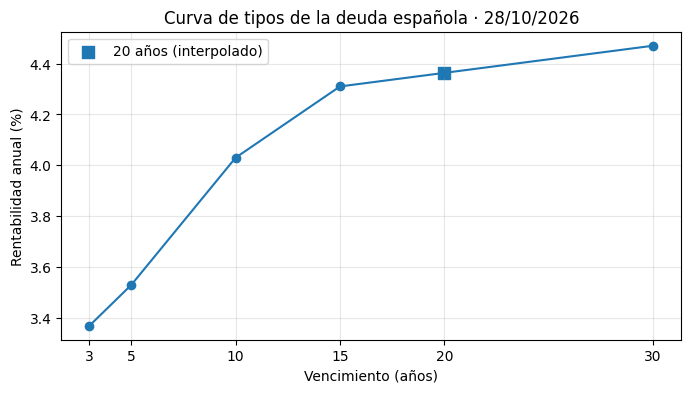

Saved: spanish_yield_curve_2026_10_28.csv


In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(curve['Years'], curve['Yield (%)'], marker='o')
plt.scatter(20, rate_20, marker='s', s=80, label='20 años (interpolado)')
plt.xticks([3, 5, 10, 15, 20, 30])
plt.xlabel('Vencimiento (años)')
plt.ylabel('Rentabilidad anual (%)')
plt.title('Curva de tipos de la deuda española · 28/10/2026')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

curve.to_csv('spanish_yield_curve_2026_10_28.csv', index=False)
print('Saved: spanish_yield_curve_2026_10_28.csv')

---
## 5. Descarga de la cartera oficial del Tesoro — 31/10/2026

La fuente primaria es la tabla web **«Bonos y Obligaciones segregables en circulación»** del [Tesoro Público](https://www.tesoro.es/es/deuda-publica/valores-del-tesoro/valores-en-circulacion). Se descargan y conservan ISIN, vencimiento y saldo nominal por emisión; no se utiliza ningún CSV transcrito por el proyecto.

**Control de fecha:** la tabla de Letras puede tener otra fecha, por lo que solo se admite la fecha indicada en la nota correspondiente a la tabla de bonos y obligaciones. Si la página ha cambiado respecto al 31/10/2026, no se genera una cartera falsamente etiquetada.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import re
import requests
from bs4 import BeautifulSoup
from IPython.display import display

TREASURY_URL = 'https://www.tesoro.es/es/deuda-publica/valores-del-tesoro/valores-en-circulacion'
TREASURY_DATE = pd.Timestamp('2026-10-31')

# Ruta de trabajo: la carpeta habitual de Colab o una carpeta local.
DRIVE_DATA = Path('/content/drive/MyDrive/Proyecto_Vivienda/02_Datos')
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

DATA_DIR = DRIVE_DATA if DRIVE_DATA.is_dir() else Path.cwd()
DATA_DIR.mkdir(parents=True, exist_ok=True)
print('Carpeta de datos:', DATA_DIR)

# Únicamente si la web ha sido actualizada y se conserva un HTML auténtico:
# OFFICIAL_HTML_SNAPSHOT = DATA_DIR / 'tesoro_2026_10_31_oficial.html'
OFFICIAL_HTML_SNAPSHOT = None


Mounted at /content/drive
Carpeta de datos: /content/drive/MyDrive/Proyecto_Vivienda/02_Datos


## 6. Lectura de la tabla, selección de emisiones y fecha de referencia

El código identifica la tabla de **bonos y obligaciones**, no la de Letras. Extrae ISIN, vencimiento y saldo publicado, y valida que la nota debajo de esa tabla corresponda al **31/10/2026**.

Si el Tesoro ya publica otra fecha, se interrumpe la ejecución. Para reproducir el 31/10/2026 posteriormente hará falta el HTML oficial guardado cuando esa fecha estaba publicada.


In [ ]:
def parse_spanish_number(value):
    text = str(value).strip().replace('\u00a0', '').replace(' ', '')
    return float(text.replace('.', '').replace(',', '.'))

def parse_treasury_page(html):
    soup = BeautifulSoup(html, 'html.parser')
    tables = soup.find_all('table')
    selected = None
    for table in tables:
        headers = ' '.join(th.get_text(' ', strip=True).lower() for th in table.find_all('th'))
        if ('vencimiento' in headers and 'saldo en circulación' in headers
                and ('coeficiente de indexación' in headers or 'valor facial' in headers)):
            if selected is not None:
                raise ValueError('Hay más de una tabla candidata de bonos y obligaciones.')
            selected = table
    if selected is None:
        raise ValueError('No se encuentra la tabla oficial de bonos y obligaciones en el HTML.')

    # La fecha debe proceder de la nota de la tabla seleccionada, nunca de la nota de Letras.
    footnote = None
    for element in selected.next_elements:
        if getattr(element, 'name', None) == 'table':
            break
        if isinstance(element, str):
            m = re.search(r'Datos\s+a\s+(\d{2}/\d{2}/\d{4})', element, re.I)
            if m:
                footnote = m.group(1)
                break
    if footnote is None:
        raise ValueError('No se ha localizado la fecha de referencia de los bonos.')
    reported_date = pd.to_datetime(footnote, dayfirst=True)
    if reported_date != TREASURY_DATE:
        raise ValueError(
            f'La tabla de bonos es del {reported_date.date()}, no del '
            f'{TREASURY_DATE.date()}. No se exporta. '
            'Conserva un HTML oficial de la fecha solicitada o utiliza otra fecha explícitamente.'
        )

    records = []
    isin_pattern = re.compile(r'\bES[A-Z0-9]{10}\b')
    for tr in selected.find_all('tr'):
        cells = tr.find_all(['td', 'th'])
        if len(cells) < 3:
            continue
        first = cells[0].get_text(' ', strip=True)
        match = isin_pattern.search(first)
        if not match:
            continue
        try:
            maturity = pd.to_datetime(cells[1].get_text(' ', strip=True),
                                      format='%d/%m/%Y')
            nominal = parse_spanish_number(cells[2].get_text(' ', strip=True))
        except (ValueError, TypeError) as exc:
            raise ValueError(f'Datos inválidos en la emisión {first}') from exc
        records.append({
            'isin': match.group(0),
            'maturity_date': maturity,
            'nominal_outstanding_million_eur': nominal,
        })
    bonds = pd.DataFrame.from_records(records)
    if bonds.empty or bonds['isin'].duplicated().any():
        raise ValueError('No se extrajeron emisiones o hay códigos ISIN duplicados.')
    if (bonds['nominal_outstanding_million_eur'] <= 0).any():
        raise ValueError('Hay nominales no positivos.')
    if (bonds['maturity_date'] < TREASURY_DATE).any():
        raise ValueError('El HTML contiene emisiones ya vencidas en la fecha de referencia.')
    return reported_date, bonds.sort_values(['maturity_date', 'isin']).reset_index(drop=True)

if OFFICIAL_HTML_SNAPSHOT is not None:
    html = Path(OFFICIAL_HTML_SNAPSHOT).read_text(encoding='utf-8')
    source_mode = 'HTML oficial conservado'
else:
    response = requests.get(TREASURY_URL, timeout=35,
                            headers={'User-Agent': 'Mozilla/5.0'})
    response.raise_for_status()
    response.encoding = response.apparent_encoding or 'utf-8'
    html = response.text
    source_mode = 'Descarga web directa'

source_date, treasury_original = parse_treasury_page(html)
print('Fuente:', source_mode, '| Fecha:', source_date.date(),
      '| Emisiones:', len(treasury_original))
display(treasury_original.head())


Fuente: Descarga web directa | Fecha: 2026-10-31 | Emisiones: 66


           isin maturity_date  nominal_outstanding_million_eur
0  ES0000012J15    2027-01-31                          22790.2
1  ES00000128P8    2027-04-30                          25929.4
2  ES0000012M77    2027-05-31                          23815.5
3  ES0000012G26    2027-07-30                          23143.6
4  ES0000012A89    2027-10-31                          25155.8

## 7. Transformaciones reproducibles y archivos generados

Las columnas publicadas se conservan en un CSV de procedencia, con los códigos ISIN. Además, se genera `tesoro_outstanding_bonds_2026_10_31_by_reference.csv`, el archivo de entrada del modelo financiero **v27**, con vencimientos, saldos nominales, años residuales, categorías de plazo y ponderaciones.

La fecha de referencia de la cartera es **31/10/2026**. El archivo `spanish_yield_curve_2026_10_28.csv` recoge los tipos de interés observados el **28/10/2026** y el tipo interpolado a 20 años.


In [ ]:
treasury_model = treasury_original[['maturity_date', 'nominal_outstanding_million_eur']].copy()
treasury_model['years_remaining'] = (
    (treasury_model['maturity_date'] - TREASURY_DATE).dt.days / 365.25
)

def maturity_bucket(years):
    if years <= 3: return '<=3'
    if years <= 5: return '3-5'
    if years <= 10: return '5-10'
    if years <= 15: return '10-15'
    if years <= 20: return '15-20'
    if years <= 30: return '20-30'
    return '>30'

treasury_model['remaining_maturity_bucket'] = (
    treasury_model['years_remaining'].map(maturity_bucket)
)
total_nominal = treasury_model['nominal_outstanding_million_eur'].sum()
treasury_model['weight_pct'] = (
    100 * treasury_model['nominal_outstanding_million_eur'] / total_nominal
)

wam = (
    treasury_model['nominal_outstanding_million_eur']
    * treasury_model['years_remaining']
).sum() / total_nominal
share_3y = (
    treasury_model.loc[treasury_model['years_remaining'] <= 3,
                       'nominal_outstanding_million_eur'].sum() / total_nominal
)
assert not treasury_model.isna().any().any()
assert abs(treasury_model['weight_pct'].sum() - 100) < 1e-8

date_tag = TREASURY_DATE.strftime('%Y_%m_%d')
official_path = DATA_DIR / f'tesoro_bonos_obligaciones_fuente_{date_tag}.csv'
model_path = DATA_DIR / f'tesoro_outstanding_bonds_{date_tag}_by_reference.csv'
html_path = DATA_DIR / f'tesoro_bonos_obligaciones_{date_tag}_original.html'

# Guardar los originales únicamente después de superar las validaciones.
html_path.write_text(html, encoding='utf-8')
treasury_original.assign(
    maturity_date=treasury_original['maturity_date'].dt.strftime('%Y-%m-%d')
).to_csv(official_path, index=False)
treasury_model.assign(
    maturity_date=treasury_model['maturity_date'].dt.strftime('%Y-%m-%d')
).to_csv(model_path, index=False)

print(f'Nominal: {total_nominal:,.1f} M€')
print(f'WAM: {wam:.4f} años')
print(f'Vencimientos <=3 años: {share_3y:.4%}')
print('Fuente HTML:', html_path)
print('Datos por ISIN:', official_path)
print('CSV para el modelo:', model_path)
display(treasury_model.head())


Nominal: 1,437,965.9 M€
WAM: 8.1821 años
Vencimientos <=3 años: 28.0961%
Fuente HTML: /content/drive/MyDrive/Proyecto_Vivienda/02_Datos/tesoro_bonos_obligaciones_2026_10_31_original.html
Datos por ISIN: /content/drive/MyDrive/Proyecto_Vivienda/02_Datos/tesoro_bonos_obligaciones_fuente_2026_10_31.csv
CSV para el modelo: /content/drive/MyDrive/Proyecto_Vivienda/02_Datos/tesoro_outstanding_bonds_2026_10_31_by_reference.csv


  maturity_date  nominal_outstanding_million_eur  years_remaining  \
0    2027-01-31                          22790.2         0.251882   
1    2027-04-30                          25929.4         0.495551   
2    2027-05-31                          23815.5         0.580424   
3    2027-07-30                          23143.6         0.744695   
4    2027-10-31                          25155.8         0.999316   

  remaining_maturity_bucket  weight_pct  
0                       <=3    1.584892  
1                       <=3    1.803200  
2                       <=3    1.656194  
3                       <=3    1.609468  
4                       <=3    1.749402  

## 8. Integración con el modelo financiero v27

La notebook principal `Spain_Public_Housing_Financing_Model_v27.ipynb` utiliza directamente los archivos `spanish_yield_curve_2026_10_28.csv` y `tesoro_outstanding_bonds_2026_10_31_by_reference.csv`, incluidos en la carpeta `data/` del repositorio.

**Estado de integración:** la versión v27 se ejecutó y se validó con estas referencias antes de su publicación. Los resultados guardados en `results/` corresponden a dicha versión; no es necesario actualizar un modelo anterior para interpretar esos resultados.

**Reproducción de fuentes históricas:** si la web del Tesoro ha cambiado, la regeneración exacta de la cartera del 31/10/2026 requiere una copia HTML oficial archivada de aquella fecha. La notebook detiene la extracción cuando la fecha de la fuente no coincide. El CSV de entrada ya validado se incluye en el repositorio para poder ejecutar el modelo financiero sin consultar la página actualizada.

**Nota de procedencia:** el archivo llamado «fuente» es una exportación de las columnas de la tabla web oficial, no un CSV que el Tesoro ofrezca directamente.
